# Bagging Predictors on the Kaggle Pima Indians Diabetes dataset
Implementation of Breiman (1996), *Bagging Predictors*, run on the Kaggle **Pima Indians Diabetes** dataset (768 patients, 8 measurements, label = diagnosed diabetic within 5 years). The same dataset appears in Breiman's Table 1 (single tree 23.4% → bagged 18.8%, on a version with the diabetic cases duplicated).

**Questions** (the paper's questions, on new data)
1. Does bagging a tree beat a single tree?
2. How many bootstrap copies are enough? (Breiman: "more than 25 is love's labor lost")
3. Does bagging a *stable* learner (1-nearest-neighbour) do anything? (Breiman: no)
4. Does the vote split tell us when the model is unsure? (confidence)
5. What does it cost in time?

**Setup**
- 80/20 stratified train/test split, repeated over **50 random splits**; every number is mean ± 95% CI across splits.
- Learner: sklearn `DecisionTreeClassifier` (unpruned CART). Bagging: sklearn `BaggingClassifier`, bootstrap samples of size N with replacement, majority vote.
- Stable comparison: 1-NN on standardized features (training statistics only).
- Speed: train time in ms, predict time in µs per patient (median across splits).


In [1]:
import time, json
import numpy as np, pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.model_selection import train_test_split
from scipy.stats import binomtest

COLS = ["pregnancies", "glucose", "blood_pressure", "skin_thickness", "insulin",
        "bmi", "pedigree", "age", "outcome"]
df = pd.read_csv("pima.csv", names=COLS)
X_all = df.drop(columns="outcome").to_numpy(float)
y_all = df["outcome"].to_numpy(int)
print("X:", X_all.shape, " diabetic:", y_all.sum(), " not:", (y_all == 0).sum())

N_SPLITS = 50  # random train/test splits
BAGS = [1, 5, 10, 25, 50, 100]


def timed(fn, repeat=1):
    ts = []
    for _ in range(repeat):
        t0 = time.perf_counter(); out = fn(); ts.append(time.perf_counter() - t0)
    return out, float(np.median(ts))


def tree():
    return DecisionTreeClassifier(random_state=0)


def knn():
    return KNeighborsClassifier(n_neighbors=1)


rec, curve, conf = [], [], []
for split in range(N_SPLITS):
    Xtr, Xte, ytr, yte = train_test_split(X_all, y_all, test_size=0.2,
                                          stratify=y_all, random_state=split)
    mu, sd = Xtr.mean(0), Xtr.std(0)
    Xtr_s, Xte_s = (Xtr - mu) / sd, (Xte - mu) / sd  # only kNN needs scaling

    # --- single tree vs bagged trees (B = 50) ---------------------------------
    for name, make, A, B in [("tree", tree, Xtr, Xte), ("knn", knn, Xtr_s, Xte_s)]:
        single, t_fit = timed(lambda: make().fit(A, ytr))
        pred, t_pred = timed(lambda: single.predict(B), 5)
        rec.append(dict(split=split, method=f"single {name}", error=100 * np.mean(pred != yte),
                        train_ms=t_fit * 1e3, pred_us=t_pred / len(yte) * 1e6))

        bag = BaggingClassifier(make(), n_estimators=50, random_state=split, n_jobs=1)
        bag, t_fit = timed(lambda: bag.fit(A, ytr))
        pred, t_pred = timed(lambda: bag.predict(B), 5)
        rec.append(dict(split=split, method=f"bagged {name} (50)", error=100 * np.mean(pred != yte),
                        train_ms=t_fit * 1e3, pred_us=t_pred / len(yte) * 1e6))

        if name == "tree":
            # vote split -> confidence
            votes = np.mean([t.predict(Xte) for t in bag.estimators_], axis=0)  # fraction voting "diabetic"
            margin = np.abs(votes - 0.5) * 2  # 0 = 25-25 split, 1 = unanimous
            for m, p, t in zip(margin, pred, yte):
                conf.append(dict(split=split, margin=m, correct=int(p == t)))

    # --- error vs number of bootstrap copies (trees) ---------------------------
    for b in BAGS:
        bag = BaggingClassifier(tree(), n_estimators=b, random_state=split, n_jobs=1).fit(Xtr, ytr)
        curve.append(dict(split=split, bags=b, error=100 * np.mean(bag.predict(Xte) != yte)))


X: (768, 8)  diabetic: 268  not: 500


In [2]:
runs, curve, conf = pd.DataFrame(rec), pd.DataFrame(curve), pd.DataFrame(conf)


def ci(x):
    x = np.asarray(x)
    return f"{x.mean():.2f} ± {1.96 * x.std(ddof=1) / np.sqrt(len(x)):.2f}"


table = runs.groupby("method", sort=False).agg(**{
    "Error % (95% CI)": ("error", ci),
    "Train (ms)": ("train_ms", lambda x: f"{x.median():.1f}"),
    "Predict (µs / patient)": ("pred_us", lambda x: f"{x.median():.1f}")})
print("\n== Main table (50 random 80/20 splits) ==\n", table.to_string())

print("\n== Error vs number of bootstrap copies (trees) ==")
curve_t = curve.groupby("bags")["error"].agg(ci)
print(curve_t.to_string())

p = runs.pivot(index="split", columns="method", values="error")
w = (p["bagged tree (50)"] < p["single tree"]).sum(); l = (p["bagged tree (50)"] > p["single tree"]).sum()
t = N_SPLITS - w - l
print(f"\nBagged tree beats single tree in {w} splits, ties {t}, loses {l}. Sign test p = {binomtest(w, w + l).pvalue:.2g}")
wk = (p["bagged knn (50)"] < p["single knn"]).sum(); lk = (p["bagged knn (50)"] > p["single knn"]).sum()
print(f"Bagged kNN beats single kNN in {wk} splits, ties {N_SPLITS - wk - lk}, loses {lk}.")

print("\n== Confidence: accuracy by vote margin (bagged trees, 50 votes) ==")
conf["bucket"] = pd.cut(conf["margin"], [-0.01, 0.2, 0.5, 0.8, 1.0],
                        labels=["close (≤60-40)", "60-40 to 75-25", "75-25 to 90-10", "lopsided (>90-10)"])
conf_t = conf.groupby("bucket", observed=True)["correct"].agg(n="size", accuracy=lambda c: f"{100 * c.mean():.1f}%")
conf_t["share"] = (conf_t["n"] / len(conf) * 100).round(1).astype(str) + "%"
print(conf_t.to_string())

table.to_csv("results_table.csv"); curve_t.to_csv("curve.csv"); conf_t.to_csv("confidence.csv")
json.dump(dict(w=int(w), l=int(l), t=int(t)), open("signtest.json", "w"))


== Main table (50 random 80/20 splits) ==
                  Error % (95% CI) Train (ms) Predict (µs / patient)
method                                                             
single tree          30.08 ± 0.98        1.1                    0.2
bagged tree (50)     23.86 ± 0.77       44.5                    9.6
single knn           29.52 ± 0.84        0.2                    2.9
bagged knn (50)      29.35 ± 0.83       17.4                  105.0

== Error vs number of bootstrap copies (trees) ==
bags
1      30.01 ± 1.09
5      26.45 ± 0.95
10     25.74 ± 0.81
25     24.62 ± 0.83
50     23.86 ± 0.77
100    23.94 ± 0.78

Bagged tree beats single tree in 49 splits, ties 0, loses 1. Sign test p = 9.1e-14
Bagged kNN beats single kNN in 12 splits, ties 37, loses 1.

== Confidence: accuracy by vote margin (bagged trees, 50 votes) ==
                      n accuracy  share
bucket                                 
close (≤60-40)     1386    56.8%  18.0%
60-40 to 75-25     1794    66.4%  23.3%


## Plots used in the slides
`curve.png`: error vs number of bootstrap copies. `confidence.png`: accuracy by how split the 50-tree vote was.

plots ok


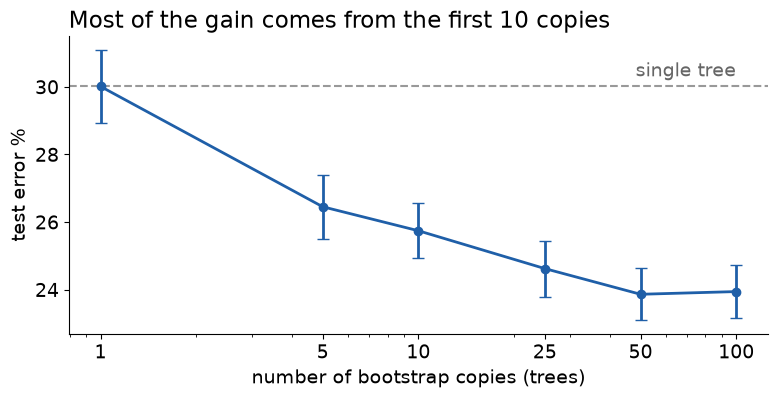

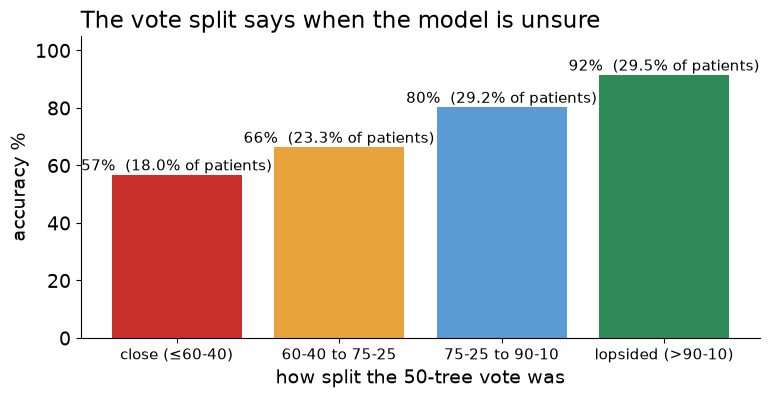

In [3]:
import pandas as pd, numpy as np, matplotlib
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 14, "axes.spines.top": False, "axes.spines.right": False})
c = pd.read_csv("curve.csv"); c[["m","pm"]] = c["error"].str.split(" ± ", expand=True).astype(float)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.errorbar(c.bags, c.m, yerr=c.pm, marker="o", lw=2, capsize=4, color="#1f5fa8")
ax.axhline(c.m[0], ls="--", color="#999"); ax.text(100, c.m[0]+0.3, "single tree", ha="right", color="#666")
ax.set_xscale("log"); ax.set_xticks(c.bags); ax.set_xticklabels(c.bags)
ax.set_xlabel("number of bootstrap copies (trees)"); ax.set_ylabel("test error %")
ax.set_title("Most of the gain comes from the first 10 copies", loc="left")
fig.tight_layout(); fig.savefig("curve.png", dpi=200)
k = pd.read_csv("confidence.csv"); k["acc"] = k["accuracy"].str.rstrip("%").astype(float)
fig, ax = plt.subplots(figsize=(8, 4.2))
bars = ax.bar(k.bucket, k.acc, color=["#c9302c","#e8a33d","#5b9bd5","#2e8b57"])
for b, s in zip(bars, k["share"]): ax.text(b.get_x()+b.get_width()/2, b.get_height()+1.5, f"{b.get_height():.0f}%  ({s} of patients)", ha="center", fontsize=11)
ax.set_ylim(0, 105); ax.set_ylabel("accuracy %"); ax.set_xlabel("how split the 50-tree vote was")
ax.set_title("The vote split says when the model is unsure", loc="left"); ax.tick_params(axis="x", labelsize=11)
fig.tight_layout(); fig.savefig("confidence.png", dpi=200); print("plots ok")

plt.show()

## How the 95% confidence interval is calculated
Each split gives one test error. The table reports mean ± 1.96 × s/√n over the n = 50 splits (s = sample standard deviation). It is a range for the *average* error, not for a single run.